# 01 · GEC model fits

Visualises `src/gec_model` output: fit quality (v2 vs the legacy v1 fits), example GEC matrices and an
empirical-vs-simulated FC comparison. Requires `python -m src.gec_model.refit`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.core import paths
from src.core.data import GROUPS, load_data, load_model_results, load_features

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"HC": "#2a9d8f", "AP": "#e76f51", "NAP": "#e9c46a"}

In [2]:
mr = load_model_results()
res, atlas = mr["results"], mr["atlas"]
labels, network = atlas["labels"], atlas["network"]
ts, sc, scores = load_data()
print(mr["settings"])

{'TR': 0.8, 'sigma': 0.01, 'a': -0.02, 'maxC': 0.1, 'lag': 1, 'delta_sigma': 0.1, 'delta_a': 0.02}


## Fit quality: v2 vs v1

fit_FC (v2)        fit_FS (v2)        iterations          fit_FC (v1)  \
             mean    std        mean    std       mean      std        mean   
group                                                                         
AP          0.783  0.035       0.763  0.042    780.000  292.973       0.616   
HC          0.770  0.030       0.743  0.037    854.167  316.872       0.624   
NAP         0.772  0.036       0.750  0.042    768.421  305.597       0.599   

             fit_FS (v1)         
         std        mean    std  
group                            
AP     0.099       0.597  0.094  
HC     0.122       0.598  0.114  
NAP    0.118       0.577  0.113

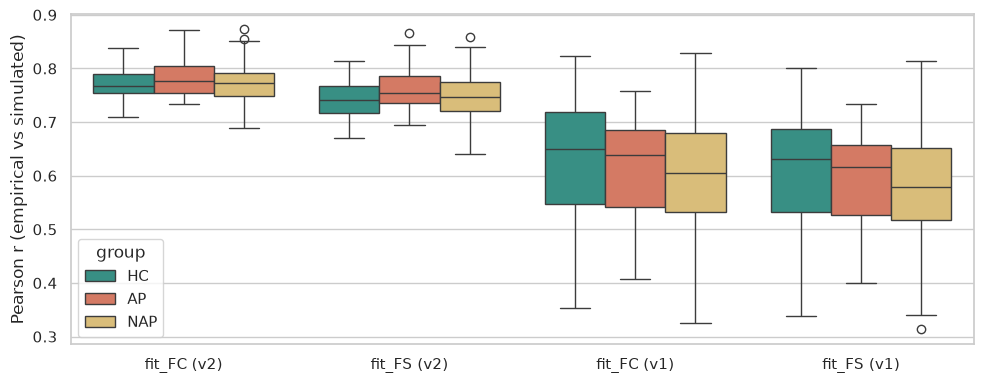

In [3]:
v1_file = paths.DATA / "derived" / "v1" / "study_results.pkl"
v1 = pickle.load(open(v1_file, "rb")) if v1_file.exists() else None
rows = []
for g in GROUPS:
    for k, r in res[g].items():
        row = {"group": g, "fit_FC (v2)": r["fit_FC"], "fit_FS (v2)": r["fit_FS"], "iterations": r["n_iter"]}
        if v1 is not None:
            row["fit_FC (v1)"] = v1[g][k]["metrics_static"]["Pearson_r"]
            row["fit_FS (v1)"] = v1[g][k]["metrics_shifted"]["Pearson_r"]
        rows.append(row)
fits = pd.DataFrame(rows)
display(fits.groupby("group").agg(["mean", "std"]).round(3))

long = fits.melt(id_vars="group", value_vars=[c for c in fits.columns if c.startswith("fit_")],
                 var_name="metric", value_name="r")
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=long, x="metric", y="r", hue="group", palette=PALETTE, ax=ax)
ax.set_ylabel("Pearson r (empirical vs simulated)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Group-mean GEC matrices (ordered by Yeo network)

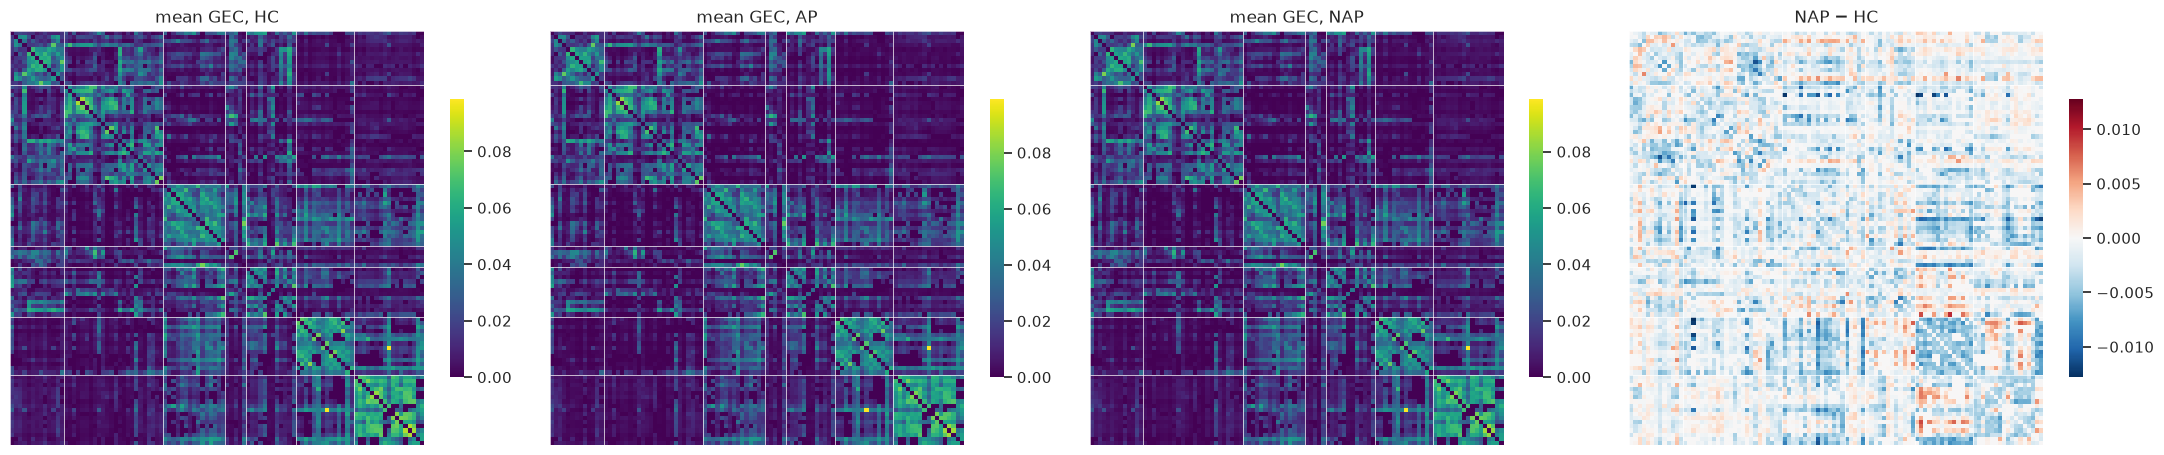

network order: [np.str_('Cont'), np.str_('Default'), np.str_('DorsAttn'), np.str_('Limbic'), np.str_('SalVentAttn'), np.str_('SomMot'), np.str_('Vis')]


In [4]:
order = np.argsort(network, kind="stable")
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, g in zip(axes, GROUPS):
    C = np.mean([res[g][k]["GEC"] for k in res[g]], axis=0)[np.ix_(order, order)]
    sns.heatmap(C, ax=ax, cmap="viridis", square=True, cbar_kws={"shrink": .6}, xticklabels=False, yticklabels=False)
    ax.set_title(f"mean GEC, {g}")
Cd = (np.mean([res["NAP"][k]["GEC"] for k in res["NAP"]], 0) - np.mean([res["HC"][k]["GEC"] for k in res["HC"]], 0))[np.ix_(order, order)]
lim = np.abs(Cd).max()
sns.heatmap(Cd, ax=axes[3], cmap="RdBu_r", vmin=-lim, vmax=lim, square=True, cbar_kws={"shrink": .6}, xticklabels=False, yticklabels=False)
axes[3].set_title("NAP − HC")
bounds = np.r_[0, np.cumsum([np.sum(network == n) for n in np.unique(network)])]
for ax in axes:
    for b in bounds: ax.axhline(b, color="w", lw=.5); ax.axvline(b, color="w", lw=.5)
plt.tight_layout(); plt.show()
print("network order:", list(np.unique(network)))

## Example subject: empirical vs simulated FC

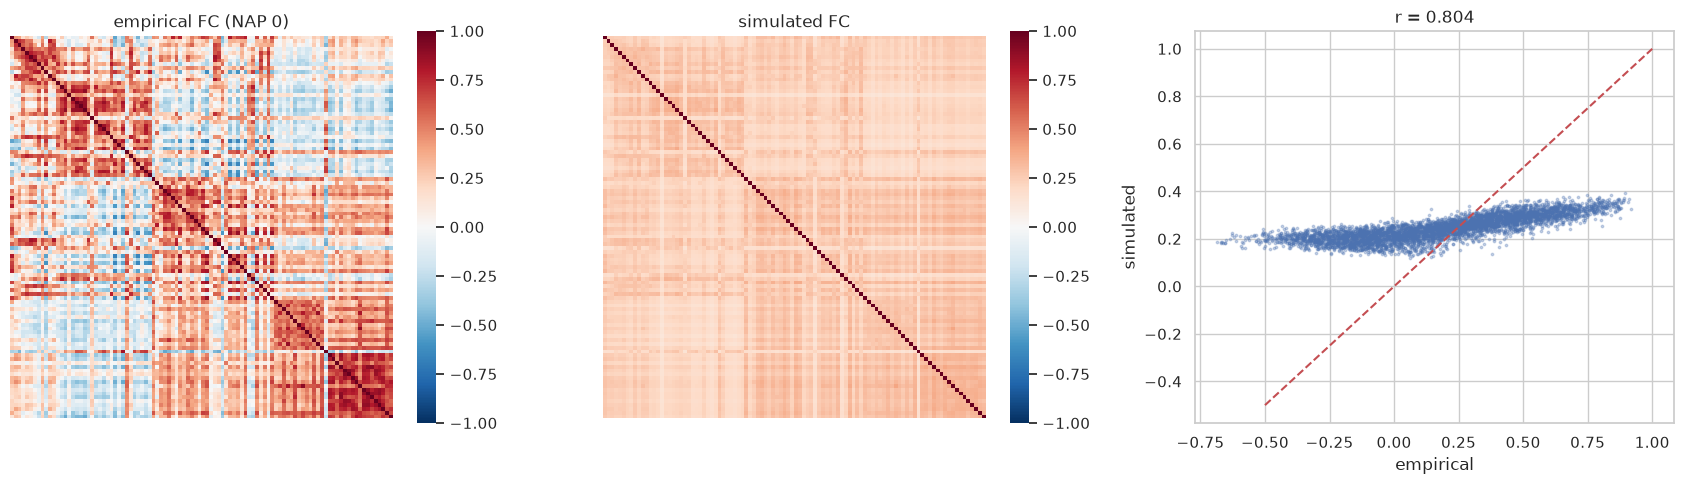

In [5]:
g, k = "NAP", 0
fc_emp = np.corrcoef(ts[g][k]); fc_sim = res[g][k]["FC_sim"]
tri = np.triu_indices(100, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.heatmap(fc_emp[np.ix_(order, order)], ax=axes[0], cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=False, yticklabels=False)
sns.heatmap(fc_sim[np.ix_(order, order)], ax=axes[1], cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=False, yticklabels=False)
axes[0].set_title(f"empirical FC ({g} {k})"); axes[1].set_title("simulated FC")
axes[2].scatter(fc_emp[tri], fc_sim[tri], s=3, alpha=.3)
axes[2].plot([-0.5, 1], [-0.5, 1], "r--"); axes[2].set_xlabel("empirical"); axes[2].set_ylabel("simulated")
axes[2].set_title(f"r = {res[g][k]['fit_FC']:.3f}")
plt.tight_layout(); plt.show()